# NLP Task 1

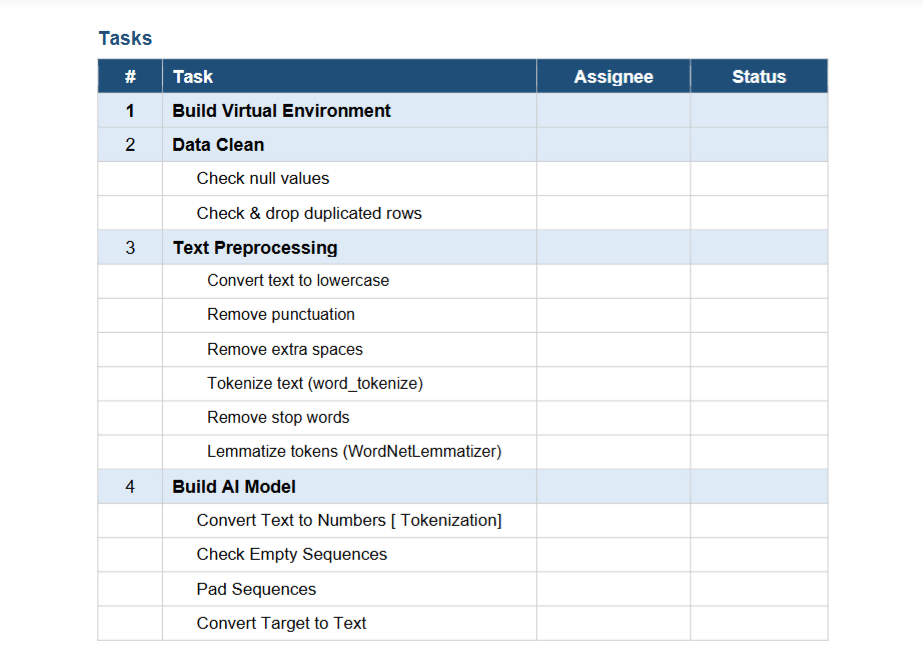

# 1. Build Virtual Environment

 create Virtual Environment using conda 
 

In [42]:
# Create a new conda environment for NLP tasks
#conda create --name nlp_tasks 

In [43]:
# Activate the NLP tasks environment
#conda activate nlp_tasks

## Setup 

In [44]:
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install nltk



#!pip install tensorflow
#!pip install google
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [45]:
import  pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string


import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')



from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## - Data

In [46]:
test=pd.read_csv("Dataset/test.csv")
df = pd.read_csv("Dataset/train.csv")
df.sample(15)

,id,keyword,location,text,target
3825,5443,first%20responders,A Hoop Somewhere,Incase of accident the first responders would ...,0
3684,5243,fatality,NaN,[Jax(MK2)] Stage Fatality:UUD+LK (Close),0
2143,3075,deaths,Your screen,real magic in real life:\n\nwomen went missing...,1
2643,3795,destruction,NaN,RSS: Russia begins mass destruction of illegal...,1
2936,4219,drowned,United States,pussy so deep I could've drowned twice,0
2149,3084,deaths,NaN,It's Time To Reduce Gun Deaths http://t.co/ilA...,1
6449,9225,suicide%20bombing,NaN,'Suicide bombing at [location named]...' #prem...,1
2134,3062,deaths,NaN,#CDCwhistleblower 2 deaths from measles compli...,1
163,237,airplane%20accident,92,#OMG! I don't believe this. #RIP bro\n#AirPlan...,1
1759,2531,collision,"USA , AZ",Anti Collision Rear- #innovation #gadgets http...,0


In [47]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=df)

#2. Data Clean

Check null values

In [48]:
df.isnull().sum()

id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

## Fill null values With NAN (thoses not important)

In [49]:
df.fillna("NAN", inplace=True)

,id,keyword,location,text,target
0,1,NAN,NAN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NAN,NAN,Forest fire near La Ronge Sask. Canada,1
2,5,NAN,NAN,All residents asked to 'shelter in place' are ...,1
3,6,NAN,NAN,"13,000 people receive #wildfires evacuation or...",1
4,7,NAN,NAN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NAN,NAN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NAN,NAN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NAN,NAN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NAN,NAN,Police investigating after an e-bike collided ...,1


## Check again after filling

In [50]:
df.isnull().sum()

id          0
keyword     0
location    0
text        0
target      0
dtype: int64

Check & drop duplicated rows

In [51]:
df.duplicated().sum()

np.int64(0)

### Check if there is same tweet (duplicated tweets)?

In [52]:
df.duplicated('text').sum()

np.int64(110)

### Show all duplicated tweets

In [53]:
#duplicated_df = df[df.duplicated('text', keep=False)].sort_values(by='text')
#sheet = sheets.InteractiveSheet(df=duplicated_df)

### Remove Duplicates

In [54]:
resolved_targets = (
    df.groupby('text')['target']
    .mean()
    .apply(lambda mean_val: 1 if mean_val >= 0.5 else 0)
)
df['target'] = df['text'].map(resolved_targets)
df.drop_duplicates(subset=['text'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)

In [55]:
df.duplicated('text').sum()

np.int64(0)

In [56]:
df.shape

(7503, 5)

#3. Text Preprocessing

Convert text to lowercase

In [57]:
df['text'] = df['text'].str.lower()

In [58]:
df['text'].sample(15)

7344         @mattmosley post a pic of your wounds please
6639                        i need a thunderstorm please!
837     sean end career sg blizzard vs knockout ... ht...
3998    tales of the #trees #deep water loving #lake t...
1330    hero's fight wars and save ppl from burning bu...
7321    i'm liable to sound like a wounded animal duri...
6398    everything has sunk in except the fact that i ...
2379    sound judgement by mpc - premature rises could...
6349    alleged driver in #kuwait attack 'joined daesh...
3620                    fatality  https://t.co/407v1y4hhg
103     320 [ir] icemoon [aftershock] | http://t.co/yn...
7296    police officer wounded suspect dead after exch...
4310    remove the http://t.co/7ieiz619h0 and linkury ...
1548       i regress and i slip and i fall off that cliff
404     arson suspect linked to 30 fires caught in nor...
Name: text, dtype: str

Remove punctuation

In [59]:
table = str.maketrans('', '', string.punctuation)

# Apply translation directly to the 'text' column
df['text'] = df['text'].astype(str).str.translate(table)
df['text'].sample(15)

1900    for some reason im listening to curfew overtim...
1403    stay tuned or dont idc casualties httptconssjp...
427                              i be on that hotboy shit
3815    aisumage akumareisu just between gray and ophe...
3615    hripsk when u do a fatality and like the corps...
1518    usa breaking news chemical spillevacuationsred...
3550    ca cops illegal immigrant with 4 prior arrests...
1219    witness video shows car explode behind burning...
234     cop pulls drunk driver to safety seconds befor...
1803    johndcgow heard this few days ago while drivin...
7349    if time heals all wounds how come the belly bu...
2776    keeps askin me what this means\nnot like i got...
2861    some days i drown in my tears but i dont let i...
825                 blizzarddraco lonewolffur i need this
5208    families to sue over legionnaires more than 40...
Name: text, dtype: str

Remove extra spaces

In [60]:
df['text'] = df['text'].astype(str).apply(lambda x: ' '.join(x.split()))
df['text'].head(15)

0     our deeds are the reason of this earthquake ma...
1                 forest fire near la ronge sask canada
2     all residents asked to shelter in place are be...
3     13000 people receive wildfires evacuation orde...
4     just got sent this photo from ruby alaska as s...
5     rockyfire update california hwy 20 closed in b...
6     flood disaster heavy rain causes flash floodin...
7     im on top of the hill and i can see a fire in ...
8     theres an emergency evacuation happening now i...
9      im afraid that the tornado is coming to our area
10          three people died from the heat wave so far
11    haha south tampa is getting flooded hah wait a...
12    raining flooding florida tampabay tampa 18 or ...
13                flood in bago myanmar we arrived bago
14    damage to school bus on 80 in multi car crash ...
Name: text, dtype: str

Tokenize text (word_tokenize)

In [ ]:
df['text'] = df['text'].astype(str).apply(word_tokenize)

In [62]:
df['text'].sample(15)

4041    [new, warning, for, central, hills, 1, hail, 6...
5656    [teamvodg, discovered, by, nickcannon, listenb...
6073    [u, know, the, music, good, when, you, hear, t...
4798    [uk, police, link, tunisian, beach, massacre, ...
5188    [refugio, oil, spill, may, have, been, costlie...
1294    [ûó, bulletproof, and, black, like, a, funera...
2232    [lisatoddsutton, the, reason, i, bring, this, ...
4941    [flood, and, mudslide, warning, for, east, fjo...
3496    [food, crematoria, provoke, outrage, amid, cri...
6460    [pixeljanosz, angelheartnight, i, remember, no...
1591    [only, one, commodity, has, escaped, the, tota...
1518    [usa, breaking, news, chemical, spillevacuatio...
5099    [we, are, now, prepared, to, obliterate, more,...
6967    [but, oh, how, rich, the, soil, how, wonderful...
6255    [sirtophamhat, scynic1, nafeezahmed, jeremydun...
Name: text, dtype: object

Remove stop words

In [63]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\loq\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [64]:
stop_words = set(stopwords.words('english'))

df['text'] = df['text'].apply(
    lambda tokens: [word for word in tokens if word.lower() not in stop_words]
)

df['text'].sample(15)

1813    [thief, broke, front, window, hicksville, stor...
5536    [newlyweds, feed, syrian, refugees, wedding, c...
6001    [nowplaying, sinking, fast, never, north, east...
6606    [love, sound, thunder, rumbling, across, mount...
3744         [monster, truck, racer, catches, fire, fair]
2280    [added, video, youtube, playlist, httptcok2bzu...
2288    [angusmacneilsnp, every, case, yes, utterly, d...
4694    [lightning, strike, distance, via, rpics, http...
3439    [aspiring, musician, amp, song, writer, shares...
4683    [dry, thunderstorms, lightning, possible, pinp...
2221    [novalismi, joseph, mallord, william, turner, ...
211     [annihilated, status, education, mba, behalf, ...
5487                            [want, rainstorm, please]
6043    [demoness, voice, angel, like, sirens, call, b...
6447    [burst, actual, tears, joy, cain, survived, su...
Name: text, dtype: object

Lemmatize tokens (WordNetLemmatizer)

---



In [65]:
lemmatizer = WordNetLemmatizer()

df['text'] = df['text'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)


In [66]:
df['text'].sample(15)

5734    [360wisenews, china, stock, market, crash, gem...
5682    [sweetpea, running, riot, allotment, brighteni...
2861                   [day, drown, tear, dont, let, get]
5058    [finnish, nuclear, plant, move, ahead, financi...
5858    [quiet, enough, literally, hear, phandom, scre...
5683    [riot, police, intervene, southampton, vitesse...
3214    [engulfed, low, selfimage, take, quiz, httptco...
751              [max, blew, tf, shot, fired, catfishmtv]
7296    [police, officer, wounded, suspect, dead, exch...
1663    [mattcohen4fake, gamma, ray, january, world, c...
334     [official, vid, gt, doublecups, gtgt, httpstco...
1106    [christopherszen, hunterlove1995, tblack, yeah...
6522    [kurtschlichter, he, already, done, negotiatin...
3965    [added, video, youtube, playlist, httptcobcjyl...
2740    [70, year, atomic, bomb, japan, still, struggl...
Name: text, dtype: object

#4. Build AI Model

Convert Text to Numbers [ Tokenization ]

In [67]:
# Initialize the Tokenizer
tokenizer = Tokenizer(oov_token='<OOV>')

# Fit on the list of lemmatized tokens
tokenizer.fit_on_texts(df['text'])

# Convert text to sequences of integers
df['sequences'] = tokenizer.texts_to_sequences(df['text'])

# Print vocabulary size and sample output
print(f'Vocabulary Size: {len(tokenizer.word_index)}')
display(df[['text', 'sequences']].head(5))

Vocabulary Size: 21280


,text,sequences
0,"[deed, reason, earthquake, may, allah, forgive...","[4072, 446, 162, 68, 1699, 4073, 7]"
1,"[forest, fire, near, la, ronge, sask, canada]","[106, 2, 163, 519, 6092, 6093, 1064]"
2,"[resident, asked, shelter, place, notified, of...","[1541, 1410, 1889, 471, 6094, 317, 191, 1889, ..."
3,"[13000, people, receive, wildfire, evacuation,...","[2569, 11, 4074, 76, 191, 379, 34]"
4,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[32, 1065, 113, 6095, 1700, 185, 76, 6096, 102]"


In [68]:
df.sample(15)

,id,keyword,location,text,target,sequences
1470,2145,catastrophe,NAN,"[catastrophe, im, perfectly, content, one, mea...",0,"[312, 5, 4684, 155, 10, 527, 511, 5, 3520, 111..."
76,112,accident,"San Mateo County, CA","[traffic, accident, n, cabrillo, hwymagellan, ...",1,"[500, 62, 528, 6206, 6207, 2172, 6208, 6209, 6..."
4816,6972,massacre,NAN,"[fake, nanking, massacre4, eyewitness, english...",1,"[1942, 16188, 16189, 494, 3017, 16190, 138, 20..."
2743,3990,devastation,"Denver, CO","[10m, settlement, attained, using, illustratio...",1,"[11753, 2982, 4923, 1074, 3719, 87, 5136, 1491..."
7392,10722,wreck,"Greenville, S.C.","[greer, man, dy, wreck, httptcon2qzbmzuly]",1,"[21114, 42, 1009, 124, 21115]"
5294,7674,panic,elena's bed // info on link,"[panic, disco, best, song, gospel, acoustic, h...",0,"[249, 1695, 88, 383, 17068, 5812, 17069]"
270,398,apocalypse,NAN,"[another, jocelyn, birthday, apocalypse]",0,"[114, 6587, 1250, 361]"
890,1298,bloody,Westchester,"[fantosex, suck, thats, youre, bloody, getting...",0,"[7830, 2261, 141, 104, 227, 145, 527, 7831]"
5373,7783,police,NAN,"[police, walk, blowin, smoke, dey, face, wan, ...",0,"[21, 1036, 17231, 185, 4361, 203, 363, 81, 336..."
4381,6340,hostages,westwestwestwestwestwestwest,"[russia, stood, cold, war, nuke, ban, face, oc...",1,"[908, 15242, 1108, 63, 2373, 1286, 203, 1288, ..."


In [69]:
df.shape

(7503, 6)

Check Empty Sequences

In [70]:
empty_seqs_count = df['sequences'].apply(lambda x: len(x) == 0).sum()
print(f'Number of empty sequences: {empty_seqs_count}')

if empty_seqs_count > 0:
    display(df[df['sequences'].apply(lambda x: len(x) == 0)].head())

Number of empty sequences: 0


Pad Sequences

In [71]:
# Calculate sequence lengths
seq_lengths = df['sequences'].apply(len)
max_len = int(np.percentile(seq_lengths, 95))
print(f'95th percentile of sequence lengths (selected max_len): {max_len}')

# Pad sequences
X = pad_sequences(df['sequences'], maxlen=max_len, padding='post', truncating='post')
print(f'Shape of input tensor X: {X.shape}')

95th percentile of sequence lengths (selected max_len): 16
Shape of input tensor X: (7503, 16)


Convert Target to Text

In [72]:
# Extract the target labels
y = df['target'].values
print(f'Shape of target array y: {y.shape}')
print(f'Target class distribution:\n{df["target"].value_counts()}')

Shape of target array y: (7503,)
Target class distribution:
target
0    4302
1    3201
Name: count, dtype: int64


In [73]:
train_text = df["text"].apply(lambda tokens: " ".join(tokens))
test_text = test["text"].apply(lambda tokens: " ".join(tokens))

y = df["target"]

In [74]:
X_train, X_valid, y_train, y_valid = train_test_split(
    train_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [75]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("svm", LinearSVC(random_state=42))
])

svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [76]:
y_valid_pred = svm_model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_valid_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

Accuracy: 0.7761
Accuracy percentage: 77.61%


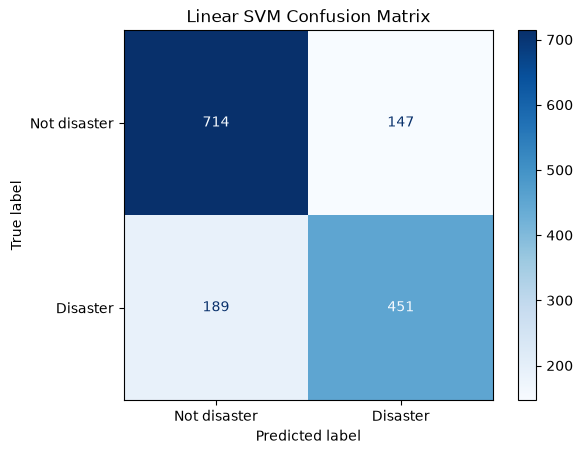

In [77]:
cm = confusion_matrix(y_valid, y_valid_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not disaster", "Disaster"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [78]:
svm_model.fit(train_text, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [80]:
test_predictions = svm_model.predict(test_text)

print(test_predictions)

[0 0 0 ... 0 0 0]
